In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn = pd.read_csv("../_supernova/results/sn_profile.csv")
bao = pd.read_csv("../_bao/results/bao_profile.csv")

comparison = pd.read_csv("results/omega_m_comparison.csv")

assert len(sn) == len(bao)
assert np.allclose(sn["Omega_m"], bao["Omega_m"])

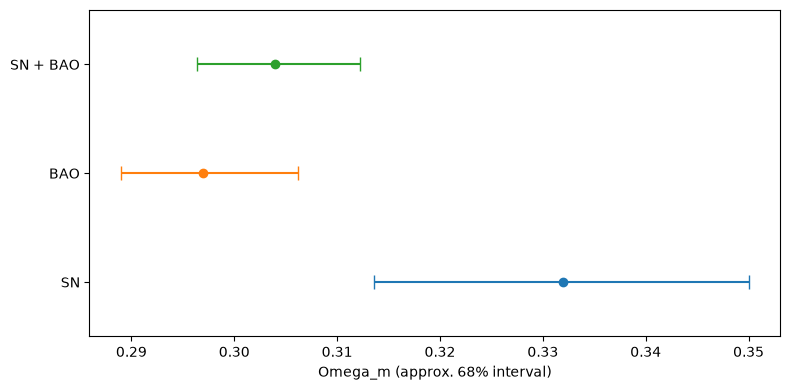

In [2]:
plt.figure(figsize=(8, 4))

for i in range(len(comparison)):
    row = comparison.iloc[i]

    plt.errorbar(
        row["Omega_m"],
        i,
        xerr=[[row["error_minus"]], [row["error_plus"]]],
        fmt="o",
        capsize=5,
    )

plt.yticks(range(len(comparison)), comparison["data"])
plt.ylim(-0.5, len(comparison) - 0.5)
plt.xlabel("Omega_m (approx. 68% interval)")
plt.tight_layout()
plt.savefig("results/omega_m_comparison.png", dpi=200)
plt.show()

In [3]:
width = comparison["upper_68"] - comparison["lower_68"]
joint_width = width[comparison["data"] == "SN + BAO"].values[0]

precision = pd.DataFrame({
    "data": comparison["data"],
    "width_68": width,
    "width_reduction_percent": 100 * (1 - joint_width / width),
})

precision.to_csv("results/interval_widths.csv", index=False)

precision

,data,width_68,width_reduction_percent
0,SN,0.036394,56.432435
1,BAO,0.017249,8.077992
2,SN + BAO,0.015856,0.000000


In [4]:
chi2_joint = sn["chi2"].values + bao["chi2"].values
best = np.argmin(chi2_joint)
omega_joint = sn.loc[best, "Omega_m"]

sn_min = min(sn["chi2"])
bao_min = min(bao["chi2"])

sn_at_joint = sn.loc[best, "chi2"]
bao_at_joint = bao.loc[best, "chi2"]

consistency = pd.DataFrame({
    "data": ["SN", "BAO", "Total"],
    "chi2_separate": [
        sn_min,
        bao_min,
        sn_min + bao_min,
    ],
    "chi2_at_joint": [
        sn_at_joint,
        bao_at_joint,
        sn_at_joint + bao_at_joint,
    ],
})

consistency["delta_chi2"] = (
    consistency["chi2_at_joint"] - consistency["chi2_separate"]
)
consistency["Omega_m_joint"] = omega_joint

consistency.to_csv("results/fit_consistency.csv", index=False)

consistency

,data,chi2_separate,chi2_at_joint,delta_chi2,Omega_m_joint
0,SN,1402.920180,1405.307545,2.387365,0.304
1,BAO,10.273934,10.832964,0.559030,0.304
2,Total,1413.194114,1416.140509,2.946395,0.304


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn_data = pd.read_csv(
    "../_supernova/processed/sn.csv",
    dtype={"CID": "string"},
)
bao_data = pd.read_csv("../_bao/processed/bao.csv")

sn_cov = np.load(
    "../_supernova/processed/sn_covariance.npz"
)["covariance"]
bao_cov = np.load(
    "../_bao/processed/bao_covariance.npz"
)["covariance"]

joint = pd.read_csv("results/joint_summary.csv")

om = joint.loc[0, "Omega_m"]
offset = joint.loc[0, "offset"]
scale = joint.loc[0, "A"]

assert sn_cov.shape == (len(sn_data), len(sn_data))
assert bao_cov.shape == (len(bao_data), len(bao_data))

In [6]:
z_sn = sn_data["zHD"].values
z_hel = sn_data["zHEL"].values

z_grid = np.linspace(0, max(z_sn), 4001)
dz = z_grid[1] - z_grid[0]

inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5
integral = np.zeros(len(z_grid))
integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

distance = (1 + z_hel) * np.interp(z_sn, z_grid, integral)
sn_model = 5 * np.log10(distance) + offset

sn_result = pd.DataFrame({
    "CID": sn_data["CID"],
    "z": z_sn,
    "observed": sn_data["m_b_corr"],
    "model": sn_model,
    "error_diagonal": np.diag(sn_cov)**0.5,
})

sn_result["residual"] = sn_result["observed"] - sn_result["model"]
sn_result["residual_scaled"] = (
    sn_result["residual"] / sn_result["error_diagonal"]
)

sn_result.to_csv("results/sn_joint_residuals.csv", index=False)

In [7]:
z_bao = bao_data["z"].values
quantity = bao_data["quantity"].values

z_grid = np.linspace(0, max(z_bao), 4001)
dz = z_grid[1] - z_grid[0]

inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5
integral = np.zeros(len(z_grid))
integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

dm = np.interp(z_bao, z_grid, integral)
dh = 1 / (om * (1 + z_bao)**3 + 1 - om)**0.5
dv = (z_bao * dm**2 * dh)**(1 / 3)

bao_shape = np.zeros(len(bao_data))
bao_shape[quantity == "DM_over_rs"] = dm[quantity == "DM_over_rs"]
bao_shape[quantity == "DH_over_rs"] = dh[quantity == "DH_over_rs"]
bao_shape[quantity == "DV_over_rs"] = dv[quantity == "DV_over_rs"]

bao_result = pd.DataFrame({
    "z": z_bao,
    "quantity": quantity,
    "observed": bao_data["value"],
    "model": scale * bao_shape,
    "error_diagonal": np.diag(bao_cov)**0.5,
})

bao_result["residual"] = bao_result["observed"] - bao_result["model"]
bao_result["residual_scaled"] = (
    bao_result["residual"] / bao_result["error_diagonal"]
)

bao_result.to_csv("results/bao_joint_residuals.csv", index=False)

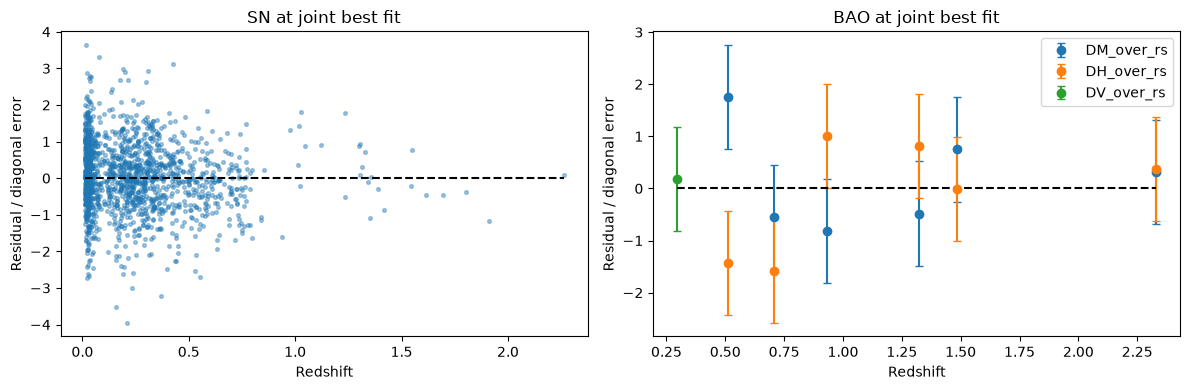

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(
    sn_result["z"],
    sn_result["residual_scaled"],
    s=7,
    alpha=0.4,
)
plt.plot([min(z_sn), max(z_sn)], [0, 0], "k--")
plt.xlabel("Redshift")
plt.ylabel("Residual / diagonal error")
plt.title("SN at joint best fit")

plt.subplot(1, 2, 2)

for name in ["DM_over_rs", "DH_over_rs", "DV_over_rs"]:
    selected = bao_result["quantity"] == name

    plt.errorbar(
        bao_result.loc[selected, "z"],
        bao_result.loc[selected, "residual_scaled"],
        yerr=np.ones(sum(selected)),
        fmt="o",
        capsize=3,
        label=name,
    )

plt.plot([min(z_bao), max(z_bao)], [0, 0], "k--")
plt.xlabel("Redshift")
plt.ylabel("Residual / diagonal error")
plt.title("BAO at joint best fit")
plt.legend()

plt.tight_layout()
plt.savefig("results/joint_residuals.png", dpi=200)
plt.show()

In [9]:
sn_white = np.linalg.solve(
    np.linalg.cholesky(sn_cov),
    sn_result["residual"].values,
)
bao_white = np.linalg.solve(
    np.linalg.cholesky(bao_cov),
    bao_result["residual"].values,
)

check = pd.DataFrame({
    "data": ["SN", "BAO", "Total"],
    "chi2": [
        np.sum(sn_white**2),
        np.sum(bao_white**2),
        np.sum(sn_white**2) + np.sum(bao_white**2),
    ],
})

check.to_csv("results/joint_chi2_check.csv", index=False)

check

,data,chi2
0,SN,1405.307545
1,BAO,10.832964
2,Total,1416.140509
